# LangGraph 控制流与节点执行


## 阅读路线与触发关系

本篇讨论控制流（章节 4）和节点执行策略（章节 5）。先判断“谁触发谁”，再判断“如何汇聚、何时退出、失败后怎么办”。

| 机制 | 解决的问题 | 注意事项 |
| --- | --- | --- |
| 固定边 / 顺序 | 确定下一步 | 编译图前声明节点和连接 |
| 条件边 / Command | 按运行时条件选择路径 | 条件边是路由函数；Command 可一起返回更新和跳转 |
| Send | 为输入项创建动态任务 | 复用已注册节点，任务数量随输入变化 |
| Fan-in（汇聚） | 汇总分支结果 | 等待所有指定分支和任一分支触发的语义不同 |
| 循环与递归限制 | 反复改进结果 | 显式停止条件优先，递归限制是保护边界 |
| 重试与缓存 | 管理一次节点执行 | 重试解决暂时失败；缓存复用相同输入的已有结果 |

这里的超步（Superstep）是一轮节点调度与状态提交，不是 Python 函数递归深度。课程中超时、错误处理与全图默认配置包含后续版本内容，复制示例前应确认安装版本支持对应参数。


## 4.1.1. add_edge


**`add_edge`** 用于在两个节点之间添加一条有向边。边是图结构中最基本的元素之一，节点之间的执行顺序、分支跳转以及循环控制，最终都依赖节点和边共同表达。

因此，在 LangGraph 中，基础的控制流结构都可以通过 **`add_edge`** 进行构建。


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)
```


```json
{
  "username": "小黄",
  "greeting": "Dear 小黄",
  "output": "Dear 小黄，你好！"
}
```


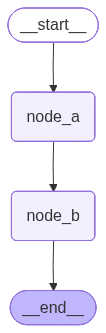

在上述示例中，图的执行流程如下：


```text
START -> node_a -> node_b -> END
```


其中：

- **`START -> node_a`** 表示图从 `node_a` 开始执行；
- **`node_a -> node_b`** 表示 `node_a` 执行完成后，继续执行 `node_b`；
- **`node_b -> END`** 表示 `node_b` 执行完成后，图进入结束状态。


## 4.1.2. add_sequence

如果需要构建一组按顺序执行的节点，也可以使用 **`add_sequence`**。

**`add_sequence`** 支持传入一个可执行对象列表。LangGraph 会按照列表顺序依次添加节点，并在相邻节点之间自动添加边。默认情况下，函数名会被用作节点名称。


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_edge(START, "node_a")
builder.add_sequence([node_a, node_b])
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)
```


```json
{
  "username": "小黄",
  "greeting": "Dear 小黄",
  "output": "Dear 小黄，你好！"
}
```


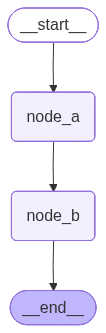

上述代码中：


```text
builder.add_sequence([node_a, node_b])
```


大致等价于：


```text
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge("node_a", "node_b")
```


因此，完整执行流程仍然是：


```text
START -> node_a -> node_b -> END
```


相比手动调用多次 **`add_node`** 和 **`add_edge`**，**`add_sequence`** 更适合用于构建简单的线性执行流程。


## 4.1.3. 省略指向 **`END`** 的边

在 LangGraph 中，图的终止并不完全依赖某个真实执行的特殊节点。

从运行机制上看，LangGraph 会在每个 **`SuperStep`** 开始时，根据当前发生更新的 **`Channel`** 以及节点之间的触发关系，计算本轮需要执行的任务列表。如果没有新的节点被激活，也就没有新的任务需要执行，图运行自然结束。

需要注意的是，**`END` 并不是运行阶段真正执行的节点**。也就是说，指向 **`END`** 的边不会像指向普通节点的边那样，触发一个真实的节点任务。它更多用于表达图结构中的“终止语义”：当前路径执行到这里即可结束。

因此，在一些简单的线性流程中，即使省略指向 **`END`** 的边，最后一个节点执行完成后，如果没有后续节点被触发，图也可以正常结束。


```python
from langgraph.graph import StateGraph, START
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)
```


```json
{
  "username": "小黄",
  "greeting": "Dear 小黄",
  "output": "Dear 小黄，你好！"
}
```


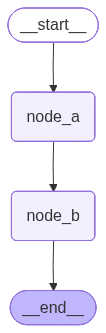

在这个例子中，虽然没有显式添加：


```python
builder.add_edge("node_b", END)
```


但是 **`node_b`** 执行完成后，没有新的节点被触发，图运行会自然结束。

不过，**可以省略指向 `END` 的边，并不表示 `END` 没有意义**。

显式添加 **`END`** 边可以让图结构更加完整，也能更清晰地表达“流程到此结束”的语义。尤其是在分支、条件跳转、循环退出等场景中，显式指向 **`END`** 通常更利于阅读和维护。

和 **`END`** 不同，**`START` 通常不能省略**。因为 **`START`** 不只是一个语义上的起点标记，它还用于告诉 LangGraph：图运行时应当从哪些节点开始执行。也就是说，下面这条边是启动图执行的关键：


```python
builder.add_edge(START, "node_a")
```


如果没有从 **`START`** 出发的边，或者没有通过其他方式指定入口节点，LangGraph 就无法确定图的初始执行节点。

因此，在实际开发中，建议保留指向 **`END`** 的边。虽然在某些简单流程中省略这些边也能正常运行，但显式添加它们，可以让图结构更加完整、语义更加清晰，便于后续维护。


## 4.2.1. 静态分支（Static Branch）


- **定义**：节点的下游候选节点 **在图编译阶段就完全确定**，只是运行时根据条件选择哪条边执行。
- 特点：
  - 下游节点集合固定，数量、目标在编译时确定
  - 运行时可选择**一个或多个**下游目标
  - 可以用来做条件分支，但不生成新的节点

⚡ 核心判断：

> **编译期知道下游集合 → 静态分支**

------


## 4.2.1.1. 并行节点

并行节点是最简单的静态分支形式。

当多个节点都从同一个上游节点触发时，它们会在同一个**超步**被激活。典型写法如下：


```python
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
```


**示例：两个节点并行执行**


```python
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
print(res)

from IPython.display import display

display(graph)
```


上述案例中，**`node_a`** 和 **`node_b`** 都由 **`START`** 触发。图运行时，二者会在**同一个超步中**被调度，它们各自读取当前状态并独立执行。

需要注意的是：

- 这里的“并行”主要指**调度语义上的并行**；两个节点之间没有先后依赖；
- 它们的输出会在当前**超步**执行完成后统一合并到状态中；
- 如果两个节点写入同一个状态字段，则该字段通常需要配置合适的 **`Reducer`**，否则可能出现状态更新冲突，抛出 **`InvalidUpdateError`** 异常


```json
{
    "topic": "猫咪",
    "poem": "《猫咪》\n夜巡檐角步轻悄，昼卧花阴晒暖毛。\n偶逐流莺穿柳过，忽惊蝴蝶上眉梢。\n\n赏析：这首作品以猫咪日常为切入点，通过“夜巡檐角”、“昼卧花阴”展现其昼伏夜出的习性，“逐流莺”、“惊蝴蝶”则捕捉其灵动瞬间。全诗未著“猫”字，却以“轻悄步”、“晒暖毛”等细节勾勒出猫咪的形神特征，尾句“上眉梢”更将好奇神态融入蝴蝶意象，物我交融，余韵悠长。",
    "joke": "有一只猫走进了一家披萨店，店员问：“您好，请问您要什么？”\n猫淡定地说：“喵～（我要一个12寸的海鲜披萨，加双倍芝士。）”\n店员愣了愣，说：“猫先生，您确定？”\n猫点点头，店员只好照做，然后猫掏出钱包付了钱，趴在小桌子上优雅地吃了起来。\n\n这时，旁边桌的客人看呆了，忍不住问店员：“它怎么能像人一样点餐、付钱、吃披萨？”\n店员耸耸肩，小声说：“我也不知道，但自从它上次用我的电脑打了一局《猫里奥》通关后，我就没敢拒绝它的任何要求。”"
}
```


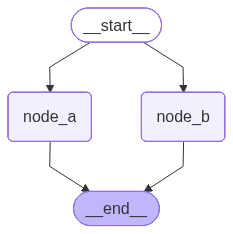


## 4.2.1.2. 条件分支

**`StateGraph`** 提供了 **`add_conditional_edges`** 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。

方法签名如下


```text
def add_conditional_edges(
    self,
    source: str,
    path: Callable[..., Hashable | Sequence[Hashable]]
    | Callable[..., Awaitable[Hashable | Sequence[Hashable]]]
    | Runnable[Any, Hashable | Sequence[Hashable]],
    path_map: dict[Hashable, str] | list[str] | None = None,
) -> Self:
```


不考虑 **`self`**，核心参数有三个：

- **`source`**：条件分支的起始节点；
- **`path`**：路由规则，是一个可执行对象，通常是函数
- **`path_map`**：路由规则的返回值到真实节点名之间的映射关系。

其中，**`path`** 的返回值表示跳转的目标节点，可以是：

- 字符串或特殊对象 **`END`** 表示的单个目标；
- 字符串或特殊对象 **`END`** 表示的多个目标组成的序列；

**`path_map`** 

- 可以省略，即取默认值 **`None`**，此时 **`path`** 返回值中出现的字符串必须是合法的节点名称。

- 可以是字典，维护 **`path`** 返回值和真实节点的映射。

- 也可以是列表，如下


```text
  path_map=["node_a", "node_b", "node_c"]
```


  相当于


```text
  path_map={
      "node_a": "node_a",
      "node_b": "node_b",
      "node_c": "node_c",
  }
```


  此时也要求 **`path`** 返回值中出现的字符串必须是合法的节点名称。

### 4.2.1.2.1. 不使用 `path_map`

如果不传 **`path_map`**，那么路由函数的返回值通常应当直接是图中的节点名称。如下


```python
def router(state: OverAllState) -> Literal["node_a", "node_b"]: 
    if "诗" in state["content_type"]: 
        return "node_a" 
    return "node_b"
```


此时，**`router`** 返回的 **`"node_a"`** 和 **`"node_b"`** 必须能够直接对应图中已经注册的节点名。

**完整案例如下**


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    return "node_b"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(START, router)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)
```


```text
============================== -> poem_res <- ==============================

{
    "topic": "布偶狗",
    "content_type": "诗",
    "poem": "《咏布偶狗》\n绒身静卧似憨眠，无骨何妨守户前。\n不吠晨昏随主步，垂髫怜抱共跚连。\n\n注：我的诗中“无骨”暗喻布偶狗没有生命骨架，却依然守护着家门；“跚连”形容孩童与布偶狗相偕学步的蹒跚之态。通过“绒身”“垂髫”等意象，既保留了布偶狗的柔软特质，又赋予其超越玩偶的温情守护之意，在静态与动态的转换间实现了拟人化的诗意升华。"
}

============================== -> joke_res <- ==============================

{
    "topic": "布偶狗",
    "content_type": "笑话",
    "joke": "有一天，一只布偶狗在街上闲逛，遇到了一只真狗。\n\n真狗好奇地问：“你是什么品种？怎么看起来毛这么长、这么滑，眼神还这么呆？”\n\n布偶狗骄傲地挺起胸膛：“我可是最顶级的仿真布偶狗！纯手工缝制，水晶眼睛，进口棉花填充，咬不坏、摔不烂，还不用溜。”\n\n真狗愣了一下，问：“那你平时都干嘛？”\n\n布偶狗叹了口气：“看家呗……主人说我最大的优点就是——丢不了，谁捡了都想还回来，因为太假了，连肉都不香。”"
}
```


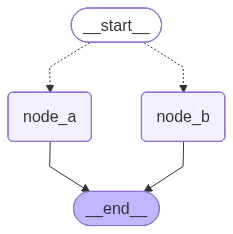

观察图结构可以发现，**`__start__`**指向**`node_a`**和**`node_b`**的线是虚线，这表示节点的跳转是有条件的，不是固定的。

### 4.2.1.2.2. 使用 `path_map`

如果不希望路由函数直接返回节点名，而是返回业务语义更强的标识，可以使用 **`path_map`** 进行映射。如下：


```python
def router(state: OverAllState) -> Literal["a", "b"]: 
    if "诗" in state["content_type"]: 
        return "a" 
    return "b"

builder.add_conditional_edges( 
    START,
    router,
    path_map={ 
        "a": "node_a", 
        "b": "node_b", 
    } 
)
```


此时返回的 **`"a"`** 和 **`"b"`** 可以不是图中已注册的节点名称，但要通过 **`path_map`** 映射到正确的节点

这种写法的好处是：

- 路由函数可以返回业务含义更清晰的标签；
- 图节点名称可以保持工程化命名；
- 渲染图结构时，边上可以显示路由标签，使图更容易理解。


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def router(state: OverAllState) -> Literal["a", "b"]:
    if "诗" in state["content_type"]:
        return "a"
    return "b"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(
    START,
    router,
    path_map={
        "a": "node_a",
        "b": "node_b",
    }
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)
```


```text
============================== -> poem_res <- ==============================

{
    "topic": "布偶狗",
    "content_type": "诗",
    "poem": "《布偶狗》\n布偶妆成似犬形，绒毛细软眼如星。\n不吠不跳乖巧坐，疑是仙童降画屏。\n\n注：我的仿写创作思路是以玩具布偶狗为意象，通过“妆成似犬形”点明其拟态特征。后三句运用比喻（眼如星）、拟人（乖巧坐）、想象（仙童降画屏）手法，赋予静态玩偶动态神韵。末句以“仙童”暗喻其灵动气质，呼应首句的“布偶”属性，使全诗在虚实之间形成童趣与仙气的张力。"
}

============================== -> joke_res <- ==============================

{
    "topic": "布偶狗",
    "content_type": "笑话",
    "joke": "好的，这里有一个关于布偶狗的笑话：\n\n有一只布偶狗，它从来不叫，也从来不跑。它的主人很担心，就带它去看兽医。\n\n兽医检查了半天，推了推眼镜说：“你这狗啊，没别的毛病，就是太乖了，乖到连狗的身份都忘了。你知道它为什么这么安静吗？”\n\n主人摇摇头。\n\n兽医叹了口气，说：“因为它是个‘布偶’，没有嘴，也没有腿。它唯一的技能，就是等你给它配个‘程序’，然后坐在那里，假装自己是一只不会乱咬东西的电子狗。说真的，这笑话比它还冷。”"
}
```


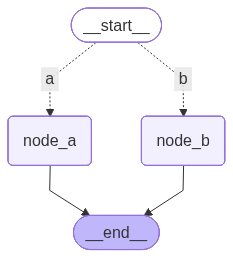

观察图结构可以发现，**`__start__`**指向**`node_a`**和**`node_b`**的虚线上出现了文本**`a`**和**`b`**，它们是路由函数返回的名称，通过**`path_map`**映射到具体的下游节点。


## 4.2.1.2.3. 同时路由至多个节点

**`add_conditional_edges`** 也支持一次路由到多个下游节点。

### 1. 不用`path_map`


```python
from collections.abc import Sequence
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(
    START,
    router
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)
```


在这个例子中：

- 当 **`content_type`** 包含 **`"诗"`** 时，同时触发 **`node_a`** 和 **`node_c`**；
- 否则同时触发 **`node_b`** 和 **`node_c`**。


**示例输出（精简）**

```text
============================== -> poem_res <- ==============================
{
    "topic": "布偶狗",
    "content_type": "诗",
    "poem": "《咏布偶狗》\n铁骨棉裘本异俦，垂头摇尾学温柔。\n非关皮相失真性，恐向人间惹旧愁。\n\n赏析：这首作品以布偶狗为题，通过“铁骨棉裘”的悖论意象，巧妙揭示材质与形态的错位。后两句笔锋一转，从拟态之“学温柔”深入至本真之“失真性”，结句“恐向人间惹旧愁”更以物喻人，赋予玩偶以灵性，暗含对世情虚伪的讽喻，余韵悠长。",
    "ci_poem": "《捣练子·布偶狗》\n针线巧，布绒柔。静卧妆台伴月幽。未解铃铛摇夜语，却随清梦上云舟。\n\n注：我的仿作将布偶狗拟人化，通过“针线巧，布绒柔”展现其手工质感，“伴月幽”营造静谧氛围。末句“随清梦上云舟”暗合现代人渴望逃离现实的隐喻，既保留古典词牌的意境美，又赋予布偶狗超越物象的情感寄托。"
}
============================== -> joke_res <- ==============================
{
    "topic": "布偶狗",
    "content_type": "笑话",
    "ci_poem": "《鹧鸪天·布偶狗》\n绒目含星尾作虹，垂蹄静卧笑春风。\n无人自戏绒球转，得主频摇铃铎浓。\n\n偎暖日，扑帘栊。娇憨总在爪痕中。\n痴心不解浮生事，一抱虚温万事空。\n\n注：本词以布偶狗为意象，通过“绒目含星”、“垂蹄静卧”等细节摹写其柔顺之态。下阕“偎暖日”、“扑帘栊”拟人化笔法，寄寓物我相忘之趣。结句“一抱虚温”暗喻繁华终归寂灭之理，将玩偶之趣升华为对生命本真的哲思。",
    "joke": "小明带他的布偶狗去宠物医院，医生检查后说：“你这狗没心跳没呼吸，已经死了。”\n小明急了：“不可能！它刚刚还对我摇尾巴！”\n医生叹了口气：“那是你兜里的钥匙串，走起路来叮当响，它尾巴上的铃铛在共振。”\n小明沉默片刻，掏出手机拍了张照发朋友圈：“我的狗死了，但它的尾巴还在听我走路。”\n评论区炸了：“建议主人也去查查脑子，可能也共振坏了。”"
}
```


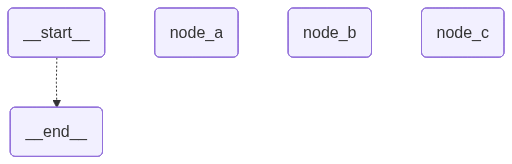

观察图结构可以发现，**`node_a`**、**`node_b`**和**`node_c`**独立于图结构之外。

和上一节案例相比，**`router`**函数返回的是序列而非单个节点，渲染器无法推断节点间的映射关系。

### 2. 添加映射

通过 **`path_map`** 显示声明映射关系，明确下游节点集合，在提升代码可读性的同时，也有助于渲染器正确展示条件边。

当前场景下 **`path`** 返回值中的字符串就是合法的节点名称，**`path_map`** 可以是字典


```python
path_map={
    "node_a": "node_a",
    "node_b": "node_b",
    "node_c": "node_c",
}
```


也可以是列表


```python
path_map=["node_a", "node_b", "node_c"]
```


**完整案例如下**


```python
from collections.abc import Sequence
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(
    START,
    router,
    path_map={
        "node_a": "node_a",
        "node_b": "node_b",
        "node_c": "node_c",
    }
    # path_map=["node_a", "node_b", "node_c"]
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)
```


**示例输出（精简）**

```text
============================== -> poem_res <- ==============================
{
    "topic": "布偶狗",
    "content_type": "诗",
    "poem": "《布偶狗》\n布偶憨然卧锦茵，牵绳随主步香尘。\n偶因客至微昂首，原是无声座上宾。\n\n注：我的创作思路是抓住布偶狗静中有动的特质。首句以“憨然卧锦茵”勾勒其静态萌态，次句“牵绳随主步香尘”暗喻宠物与人的陪伴关系。转句“偶因客至微昂首”捕捉其反应，既保留布偶的拟真特性，又暗示机械性动作。结句“原是无声座上宾”点明其非生物属性，与开篇“布偶”形成闭环。全诗通过动静、真假的微妙转化，赋予静物以灵性。",
    "ci_poem": "《醉花阴·布偶狗》\n绒耳垂垂星作眸，憨卧小窗幽。棉絮裹憨态，线描眉眼，缝就三分柔。\n旧尘不染春衫袖，伴我度春秋。虽无温舌语，月斜人静，也解倚床头。\n\n注：我以拟人笔法赋予布偶狗灵性，通过“绒耳垂垂”“棉絮裹憨态”等细节勾勒其柔软形态，又于“月斜人静”处暗藏陪伴深情。下阕“旧尘不染”暗喻其纯净守护，末句“解倚床头”更将静物写活，道出玩偶与主人之间无声的慰藉。"
}
============================== -> joke_res <- ==============================
{
    "topic": "布偶狗",
    "content_type": "笑话",
    "ci_poem": "《南歌子·布偶狗》\n绒耳垂春水，圆睛印月痕。\n棉絮缝成憨态真。\n不向朱门摇尾，卧蓬门。\n\n旧线牵云袖，新绒补雪身。\n线头散作泪斑纹。\n但把残年缝进，掌中温。\n\n注：我的布偶狗，是外婆用旧棉裤的棉花和二姐穿小的灯芯绒外套一针一线缝成的。二十年过去，棉絮从它破了洞的耳朵里露出，像吐着舌头。我模仿陆游“我与狸奴不出门”的意境，通过“棉絮缝春水”喻指时光在针脚里流逝，而“线头泪斑”则是故意缝补的裂痕——我们总要在破碎的事物里，重新认出圆满的形状。",
    "joke": "好的，这是一个关于布偶狗的笑话：\n\n有一只布偶狗，它特别特别懒，懒到什么程度呢？它的主人叫它去捡飞盘，它都懒得动。主人决定训练它，就扔出一个飞盘，大声喊：“布偶，快去捡！”\n\n布偶狗懒洋洋地抬头看了一眼飞盘落在远处，然后又趴下了。主人很生气，又扔了一个，它还是不理。\n\n主人无奈，只好采取了终极手段——假扮成一只会动的布偶狗，自己冲过去把飞盘叼了回来。\n\n布偶狗一看，浑身毛发都惊得炸了起来，它对旁边的一只小花狗低声说：“天哪，你看，那玩意儿居然能自己动！它还是个永动机！吓死狗了，好赖哦！”"
}
```


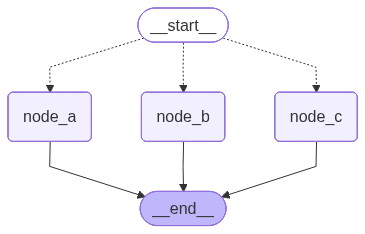

如图所示，图结构被正确渲染。


## 4.2.1.3. defer node execution

某些情况下，我们希望在所有常规任务节点执行完毕后，再进行日志、审计等收尾工作

此时可以在添加节点时设置**`defer=True`**，如下：


```python
builder.add_node("audit_node", audit_node, defer=True)
```


**`defer=True`** 的含义是：

当前节点不会在其被触发后立即执行，而是被延迟到常规图运行流程结束后，再在**额外的超步中**触发执行。

这类节点适合用于：

- 日志记录；
- 审计检查；
- 结果汇总；
- 收尾清理；
- 统一校验前面节点是否已完成。

### 4.2.1.3.1. 底层实现机制

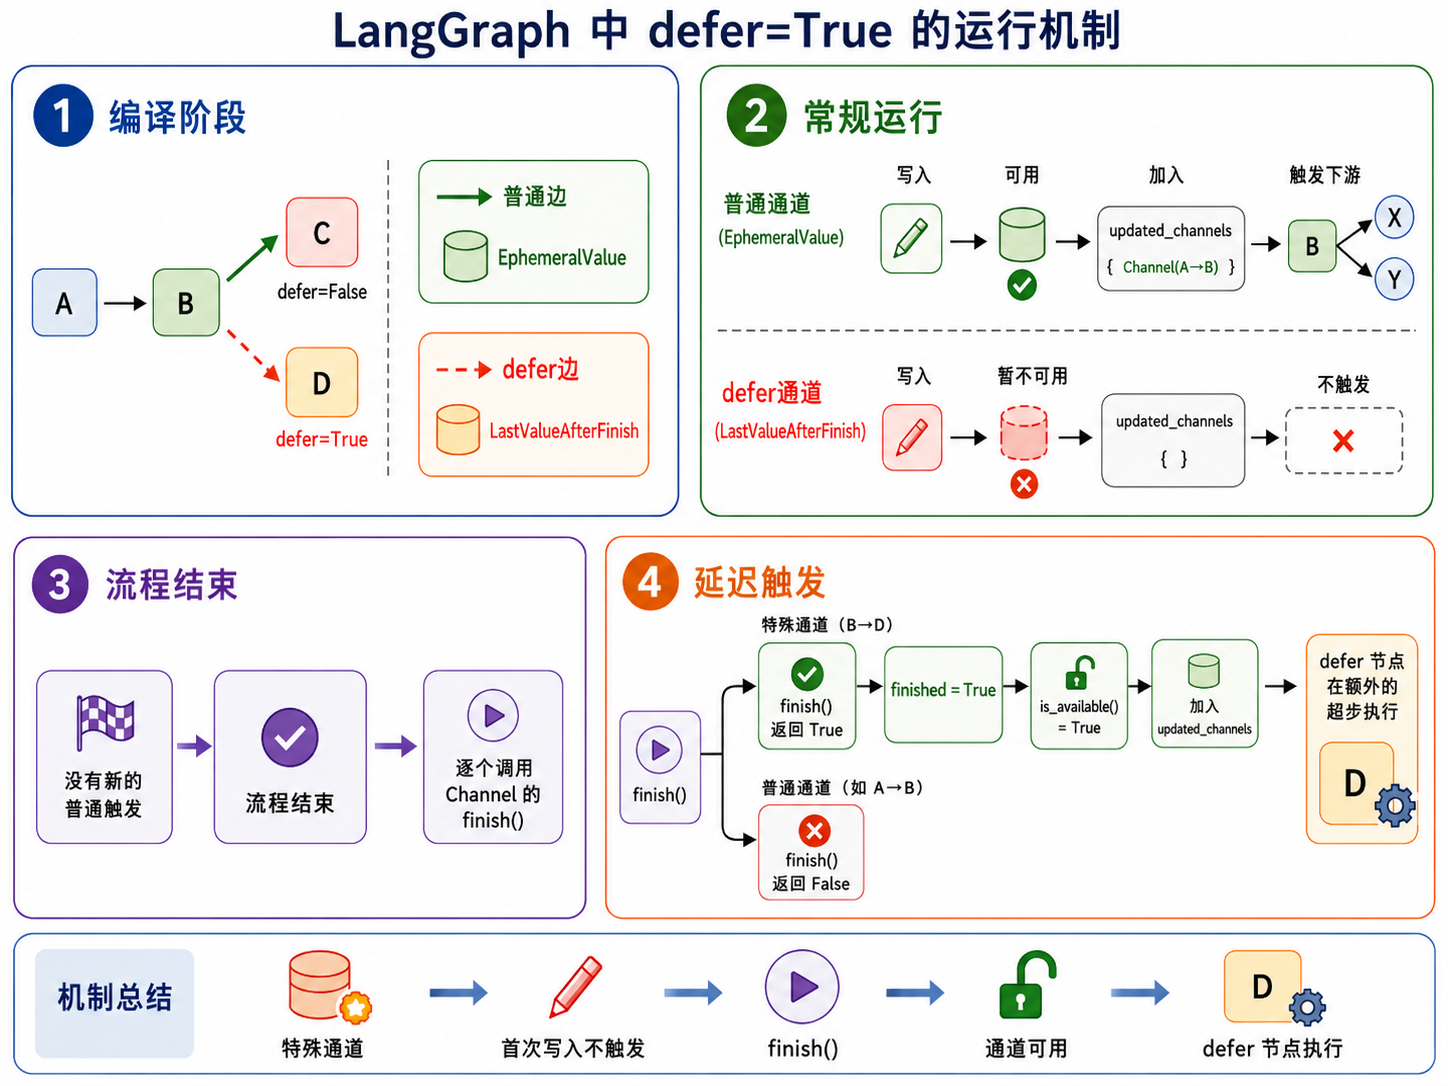

#### 1. 编译阶段：使用特殊 Channel

1. **`LangGraph`** 在编译状态图时，会为边创建对应的 **`Channel`**。

2. 此时会根据节点的 **`defer`** 属性创建不同类型的 **`Channel`**，如下。


```text
   self.channels[branch_channel] = (
       LastValueAfterFinish(Any)
       if node.defer
       else EphemeralValue(Any, guard=False)
   )
```


   **`defer`** 默认值为 **`False`**

   对于普通节点，边对应的通道类型是 **`EphemeralValue`**，可以理解为普通临时通道；而对于 **`defer=True`** 的节点，边对应的通道类型是特殊的 **`LastValueAfterFinish`**。

#### 2. 常规运行阶段-写入但不触发

1. 在图运行过程中，每个节点执行完成后，会向其下游边对应的 **`Channel`** 写入数据。
2. 常规的 **`Channel`** 在运行开始后处于可用状态，被写入后记录在 **`updated_channels`** 列表中，从而在下一个超步中触发下游节点的执行。
3. 但是，**`LastValueAfterFinish`** 类型的通道起初是不可用的，首次被写入时不会添加到 **`updated_channels`** 列表中，下游节点自然不会被触发。

#### 3. 常规流程结束后：调用`finish()`唤醒延迟节点

1. **`LangGraph`** 底层用 **`trigger_to_nodes`** 维护了 **边的 `Channel` -> 节点** 的映射，是一个字典。
2. 在每个超步结束后，运行时会根据 **`updated_channels`** 判断是否还有新的节点需要被触发。
3. 如果 **`updated_channels`** 和 **`trigger_to_nodes`** 的 key 没有交集，说明当前没有新的普通节点需要继续执行，常规运行流程已结束。
4. 此时，**`LangGraph`** 运行时会调用所有 **`Channel`** 的 **`finish()`** 方法。
5. 对于普通 **`Channel`** ，**`finish()`** 通常不会产生新的触发效果；但对于 **`LastValueAfterFinish`** 类型通道，首次调用 **`finish()`** 时，会将内部的 **`finished`** 标记设置为 **`True`**，并返回 **`True`**。
6. 一旦 **`finished=True`**，该通道的 **`is_available()`** 就会变为 **`True`**。
7. 于是，原本被延迟的通道会被加入 **`updated_channels`**，从而在额外的超步中触发对应的 **`defer`** 节点。

#### 4. 总结

因此，**`defer=True`** 的运行机制可以概括为：

> 触发边的 **`Channel`** 为特殊类型，首次写入不触发；常规流程结束后，特殊通道 **`finish()`**；通道变为可用；从而触发延迟节点，后者在额外超步中执行。

### 4.2.1.3.2. 案例


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from loguru import logger

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点全部执行完毕，诗 {'已生成' if state['poem'] else '未生成'}，笑话 {'已生成' if state['joke'] else '未生成'}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("audit_node", audit_node, defer=True)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
print(res)

from IPython.display import display

display(graph)
```


在这个图中：

- **`node_a`** 和 **`node_b`** 是普通节点，在常规流程中被触发；
- **`audit_node`** 虽然也由 **`START`** 触发，但由于设置了 **`defer=True`**，不会立即执行；
- **`node_a`** 和 **`node_b`** 都执行完成后，常规运行流程结束，**`audit_node`** 才会在额外的超步中执行；
- 因此，**`audit_node`** 中可以读取到 **`node_a`** 和 **`node_b`** 已经写入并提交后的状态。


**示例输出（精简）**

```text
{
    'topic': '布偶狗',
    'poem': '《咏布偶狗》\n'
            '绸身棉腑自憨娇，静卧无眠守寂寥。\n'
            '不吠不嗔街巷事，偎人一晌解无聊。\n'
            '\n'
            '注：我的创作思路是通过拟人化手法，赋予布偶狗以温柔静默的品格。'
            '首句以“绸身棉腑”点明材质，次句“守寂寥”暗合宠物陪伴的特质。'
            '后两句通过“不吠不嗔”与“解无聊”的对比，凸显布偶狗无声胜有声的治愈力量，'
            '在机械玩物中注入人文温度。',
    'joke': '这是一个关于布偶狗的笑话：\n'
...（中间日志/重复事件省略）...
            '\n'
            '最后，活狗叹了口气，对主人说：\n'
            '\n'
            '“主人，这只狗……是不是在用‘静默模式’跟我交流？'
            '它的蓝牙是不是断了？”'
}
```


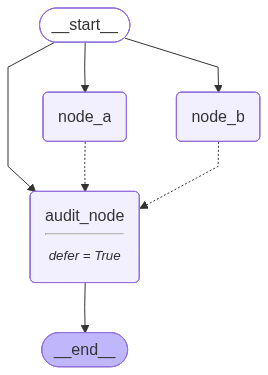

### 4.2.1.3.3. 小结

**`defer=True`** 适合“最后执行”的收尾节点。

它的本质是通过特殊的 **`Channel`** 控制触发时机：

1. 编译阶段为延迟节点创建 **`LastValueAfterFinish`** 类型通道；
2. 常规运行阶段该通道可以被写入，但不可用，不会触发下游节点；
3. 常规流程结束后调用通道的 **`finish()`** 方法；
4. **`finish()`** 首次生效后将通道标记为可用；
5. 延迟节点在额外超步中被触发执行。

> 因此， **`defer=True`** 将节点的触发信号延迟释放，使该节点在常规流程结束后执行。


## 4.2.2. 动态分支（Dynamic Branch）

- **定义**：节点的后续执行路径在 **运行时** 才确定，可以根据当前状态、输入数据或中间结果，动态决定要触发哪些下游任务或跳转到哪个下游节点。
- 特点：
  - 下游执行目标可以在运行时选择；
  - 下游任务数量可以在运行时决定；
  - 可以为同一个下游节点动态创建多个执行任务；
  - 适合实现 Map-Reduce 式动态扇出、多任务并行处理、运行时条件跳转等场景。
  
  需要注意的是，所谓“动态”通常不是指运行时临时创建新的节点定义。节点本身一般仍需要在图编译前注册。动态性主要体现在：**运行时决定触发哪些节点，以及为这些节点创建多少个执行任务**。
- 典型用法：
  - **`Send`**（动态扇出任务/数据）
  - **`Command(goto=...)`**（运行时跳转到下游节点）

⚡ 核心判断：

> **运行时决定后续执行目标或任务数量 → 动态分支**


## 4.2.2.1. 并行节点

**`Send`** 结合 **`add_conditional_edges()`** 使用，可以用于动态扇出任务

所谓**扇出（Fan-out）**，是指一个上游节点像扇子一样，向外分发出多个下游任务。例如，根据一个主题，同时生成诗、词、笑话三个任务；又如，根据一个列表，为列表中的每个元素动态启动一个处理任务。

具体来说，路由函数可以返回一个 **`Send`** 实例序列。每个 **`Send`** 实例都描述了一次独立的任务分发：

- 分发到哪个下游节点；
- 给这个下游节点传入什么私有状态。

运行时，**`LangGraph`** 会根据返回的每个 **`Send`** 实例创建对应的任务。这些任务通常会在同一个超步中并行执行。

**`Send`** 类构造器源码如下


```python
def __init__(self, /, node: str, arg: Any) -> None:
    """
    Initialize a new instance of the `Send` class.

    Args:
        node: The name of the target node to send the message to.
        arg: The state or message to send to the target node.
    """
    self.node = node
    self.arg = arg
```


该构造器接收两个参数，并记录为实例属性：

- node：待启动的下游节点名称，必须是已在状态图中注册的合法名称
- arg：传递给下游节点的信息，仅对**`node`**指向的节点可见，通常应是私有状态。每个 **`Send`** 实例接收到的 **`arg`** 是独立的，互不相干。

**实例如下**


```python
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatDeepSeek(
    model = "deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]

    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

def router(state: InputState) -> Sequence[Send]:
    prompt = "请生成关于 {} 的 {}"
    english2chinese = {
        "poem": "一首诗",
        "ci_poem": "一首词",
        "joke": "一个笑话"
    }

    topic = state["topic"]

    return [Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": prompt.format(topic, english2chinese[content_type]),
            }
        ) for content_type in CONTENT_TYPES
    ]

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"]
)
builder.add_edge("worker_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
print(res)

from IPython.display import display
display(graph)
```


在这个案例中，**`router()`** 并没有直接返回某一个固定的下游节点名称，而是返回了多个 **`Send`** 实例：


```text
[ 
    Send("worker_node", {"content_type": "poem", ...}), 
    Send("worker_node", {"content_type": "ci_poem", ...}), 
    Send("worker_node", {"content_type": "joke", ...}), 
]
```


因此，运行时会动态创建三个指向 **`worker_node`** 的任务。三个任务执行的是同一个节点函数，但它们接收到的私有状态不同，所以可以分别生成**诗、词和笑话**。


**示例输出（精简）**

```text
{
  "poem": "## 《布偶狗》\n\n它曾蜷在藤椅里数谷粒，\n一只耳朵垂向磨损的地板。\n现在檐角的水滴是它的心跳，\n牵动穿珠眼珠转动。\n\n穿碎花裙的小女孩，\n用膝盖丈量过它的静默。\n她松开橡皮筋的午后，\n线缝里渗出稚嫩的气流。\n\n有人将米尺抖成琴弦，\n折叠的假寐里，\n它代替远方的稻草人，\n在积雨的布纹中扎根。\n\n田野在练习告别，\n而它守着发芽的梯田。\n当月光填满每道接缝，\n皮毛间涌出成群的往事。",
  "ci_poem": "《临江仙·布偶狗》\n绒作皮毛棉作骨，琉璃眸底春凝。\n也无吠影也无惊。倚床垂耳听，抱主索糖迎。\n\n不向残羹争冷炙，旧衾犹带余馨。\n学人解语却无声。偶沾星与月，懒问雨和晴。\n\n注：我以布偶狗为题，通过“绒作皮毛棉作骨”等句，以拟人手法赋予玩偶灵性。下阕“不向残羹争冷炙”暗喻玩偶超然物外的品性，末句“偶沾星与月”更添空灵意境，将玩偶与自然意象相融，表达出静默相伴的永恒温馨。",
  "joke": "# 布偶狗的笑话\n\n有一天，一只布偶狗走进一家宠物店，对店主说：\n\n“老板，我想买一只真正的狗朋友。”\n\n店主看了看它，好奇地问：“你不是狗吗？”\n\n布偶狗叹了口气，说：“唉，我是布偶做的，只能陪主人睡觉和卖萌，但我不会汪汪叫，也不会摇尾巴，更不会追球。每次主人想带我出去散步，我只能在包里安静地坐着，感觉自己特别没用。”\n\n店主笑了笑，说：“那你想要什么样的狗朋友？”\n\n布偶狗眼睛一亮：“我想要一只真正的狗，可以带着我去跑、去叫、去玩！我要学习怎么当 …（该行元数据省略）
}
```


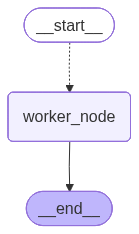

此处图结构能成功渲染的关键，是在 **`path_map`** 中显式声明了可能被路由到的下游节点：


```python
path_map=["worker_node"]
```


因为 **`Send`** 的目标和数量可以运行时动态决定，图渲染器无法仅靠运行时返回值提前知道图结构。通过 **`path_map`** 声明候选下游节点后，渲染图才能正确展示 **`START`** 到 **`worker_node`** 的条件边关系。

补充说明：如果多个并行任务写入同一个状态字段，通常需要为该字段定义 reducer，用于合并多个任务的输出。本例中三个任务分别写入 **`poem`**、**`ci_poem`**、**`joke`** 三个不同字段，因此不会发生同一字段的并发合并问题。

---


## 4.2.2.2. 条件分支

### 4.2.2.2.1. Command介绍

**`Command`** 是 **`LangGraph`** 中用于控制图执行的多功能原语，它的构造器可以接受四个参数，并记录在同名类属性中：

- **`update`**：更新图状态，效果等同于节点直接返回状态更新字典；
- **`goto`**：指定节点执行完成后的跳转目标，可用于运行时条件分支。当需要同时更新状态并控制跳转时，比单独使用条件边更合适；
- **`graph`**：存在子图时，用于指定跳转发生在哪一层图中，例如从子图跳转到父图；
- **`resume`**：用于恢复被中断的图执行，常见于 **`human-in-the-loop`** 场景。

### 4.2.2.2.2. 用`Command`实现条件分支

可以通过 **`Command(goto=...)`** 在节点内部实现条件分支。

与 **`add_conditional_edges()`** 相比，**`Command`** 更适合“状态更新”和“控制流跳转”需要放在同一个节点返回值中的场景。

例如，一个节点既要更新状态，又要根据当前状态决定下一步跳转目标，就可以返回：


```python
return Command(
    update={"foo": "bar"},
    goto="next_node"
)
```


```python
from typing import TypedDict, Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", END]]:
    content_type = state["content_type"]

    if content_type == "poem":
        return Command (
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command (
            goto="joke_node"
        )
    return Command (
        goto=END
    )

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content

    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content

    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})

# 这里故意传入一个不符合 Literal["poem", "joke"] 的值，
# 用来观察运行时兜底分支。
# 注意：Literal 主要服务于静态类型检查，
# 默认不会在 Python 运行时阻止非法值传入。
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

from IPython.display import display
display(graph)
```


上述代码中，**`router()`** 节点根据 **`content_type`** 的值决定下一步跳转目标：

* 当 **`content_type == "poem"`** 时，跳转到 **`poem_node`**；
* 当 **`content_type == "joke"`** 时，跳转到 **`joke_node`**；
* 当传入其他非法值时，跳转到 **`END`**，图直接结束。

**结果如下**


```text
============================== -> poem <- ==============================
{
    'topic': '布偶猫',
    'content_type': 'poem',
    'poem': '《布偶猫》\n雪砌绒身碧眼秋，一帘幽梦卧云舟。\n忽听银铃摇碎月，轻衔星子入西楼。\n\n（注：此诗通过“雪砌绒身”、“碧眼秋”等意象勾勒布偶猫雪白柔顺的毛发与澄澈眼眸；“卧云舟”、“衔星子”等超现实笔法，赋予其精灵般的气质；末句“入西楼”暗合其优雅步态与神秘秉性，整体形成月光浸染的梦幻意境。）'
}

============================== -> joke <- ==============================
{
    'topic': '布偶猫',
    'content_type': 'joke',
    'joke': '给你分享一个关于布偶猫的冷笑话：\n\n---\n\n有一天，一只布偶猫跑去宠物店里应聘。  \n店员问：“你有什么特长呢？”  \n布偶猫懒洋洋地回答：“我特别软。”  \n店员说：“还有呢？”  \n猫翻个身，露出肚皮：“你看，我连摸都不需要自己动——你只要一伸手，我自己就‘布偶’过去了。”\n\n---\n\n希望能让你会心一笑（或者冷到打个哆嗦）😺❄️'
}

============================== -> illegal <- ==============================
{
    'topic': '布偶猫',
    'content_type': 'illegal'
}
```


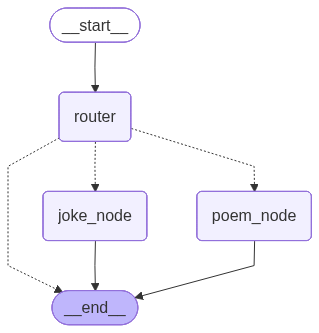

这里使用：


```python
Command[Literal["poem_node", "joke_node", END]]
```


作为 **`router()`** 的返回值类型注解。

注解不能限制 **`goto`** 在运行时只能写这些值，而是为了让 LangGraph 和类型检查工具知道：这个节点可能跳转到哪些目标。对于图结构渲染来说，这个注解非常重要。如果不声明，渲染出来的图可能无法正确表达 **`router`** 节点的潜在跳转关系。

需要注意的是，如果某个节点使用 **`Command(goto=...)`** 控制后续跳转，一般不要再给这个节点额外添加普通下游边。否则，普通边和 **`Command`** 指定的跳转都可能生效，导致多个下游节点被同时触发。

因此，本例中只添加：


```python
builder.add_edge(START, "router")
```


而不添加类似下面这样的边：


```python
builder.add_edge("router", "poem_node")
builder.add_edge("router", "joke_node")
```


因为 **`router`** 的后续跳转已经由 **`Command(goto=...)`** 决定。

---


## 4.2.2.3. 小结

动态分支有两类典型应用场景：

| 场景     | 典型 API                                   | 说明                                        |
| -------- | ------------------------------------------ | ------------------------------------------- |
| 动态扇出 | **`Send`** + **`add_conditional_edges()`** | 运行时创建多个任务，常用于 **`Map-Reduce`** |
| 动态跳转 | **`Command(goto=...)`**                    | 节点内部根据状态决定跳转目标                |

二者的区别如下：

* **`Send`** 更强调“一个节点动态分发多个任务实例”；
* **`Command(goto=...)`** 更强调“当前节点执行完后动态跳转到哪个节点”。

> **`Send` 解决的是：运行时要启动多少个任务实例。**
> **`Command(goto=...)` 解决的是：当前节点执行完后要去哪里。**

不过，无论是 **`Send`** 还是 **`Command(goto=...)`**，目标节点通常都需要提前注册到图中。所谓“动态”，主要是运行时动态决定任务数量、任务输入或跳转路径，而不是运行时临时创建新的节点。


## 4.3. 多分支汇聚：Fan-in

上文提到了**扇出（Fan-out）**，它是指像打开扇子一样，由一个上游节点分发出多个下游分支。

与之相对，**扇入（Fan-in）**是指像合拢扇子一样，多个上游分支汇聚到同一个下游节点。

**Fan-out** 对应的是“分支结构”，**Fan-in** 对应的是“多分支汇聚结构”。


## 4.3.1. 静态扇入

在计算机中，**“与”**表示两个或多个条件同时满足，而**“或”**表示两个或多个条件任意一个满足。

当多个上游分支同时汇入同一个下游节点时，根据触发条件的不同，可以分成两种情况：

- **“与”**触发：上游所有分支全部到达才可触发下游节点
- **“或”**触发：任意一个分支到达，都可以触发下游节点

需要注意，这里的 **“与 / 或”** 只是帮助理解的类比，并不是 **`LangGraph`** 的官方术语。


## 4.3.1.1 **“与”**触发：等待所有上游分支到达

这是多分支汇聚中**最常见**的情况。

**`LangGraph`** 的计算图是在一系列超步中完成的，如果能看到每个节点实例运行时的超步编号，则节点执行顺序一目了然。

**`LangGraph`** 的节点可以通过名为 **`config`** 的有名参数获取运行时配置

**`config`** 的元数据中记录了当前节点所在的 **`SuperStep`** 序号，可以通过下面的方式获取：


```python
config["metadata"]["langgraph_step"]
```


**详见下文。**


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
builder.add_edge(["node_c", "node_d"], "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)
```


```text
2026-06-05 14:55:01.705 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-06-05 14:55:01.708 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-06-05 14:55:01.710 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-06-05 14:55:01.713 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-06-05 14:55:01.714 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发
```


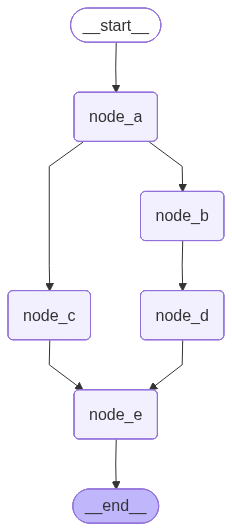

由运行结果可知：

* **`node_a`** 在第 1 个超步执行；
* **`node_b`** 和 **`node_c`** 在第 2 个超步并行执行；
* **`node_d`** 在第 3 个超步执行；
* **`node_e`** 在第 4 个超步执行。

虽然 **`node_c`** 在第 2 个超步已经执行完成，但是 **`node_e`** 并不会立刻触发。
因为这里使用的是：


```python
builder.add_edge(["node_c", "node_d"], "node_e")
```


这表示 **`node_e`** 需要等待 **`node_c`** 和 **`node_d`** 两个上游节点全部完成后，才会被触发一次。

因此，这种写法对应的是 **“与”触发**：等待所有上游分支到达方可触发。


## 4.3.1.2 **“或”**触发：任意上游分支到达即可触发

另一种情况是：多个上游分支分别连接到同一个下游节点，但它们之间没有显式的同步等待关系。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")

# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)
```


```text
2026-06-05 15:09:11.715 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-06-05 15:09:11.720 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-06-05 15:09:11.723 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-06-05 15:09:11.729 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-06-05 15:09:11.729 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-06-05 15:09:11.732 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发
```


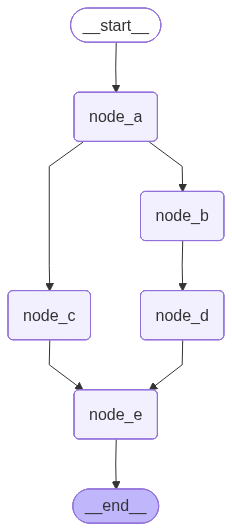

从运行结果可以看出，**`node_e`** 被触发了两次：

1. **`node_c`** 在第 2 个超步执行完成后，触发 **`node_e`** 在第 3 个超步执行；
2. **`node_d`** 在第 3 个超步执行完成后，再次触发 **`node_e`** 在第 4 个超步执行。

原因是这里使用了两条独立的边：


```python
builder.add_edge("node_c", "node_e")
builder.add_edge("node_d", "node_e")
```


这表示 **`node_c`** 和 **`node_d`** 都可以分别触发 **`node_e`**，它们之间没有同步等待关系。

因此，这种写法对应的是 **独立触发**，也可以类比为 **“或”触发**。

需要特别注意：


```python
builder.add_edge(["node_c", "node_d"], "node_e")
```


和


```python
builder.add_edge("node_c", "node_e")
builder.add_edge("node_d", "node_e")
```


不是等价写法。

前者表示 **等待多个上游全部完成后才触发一次**；
后者表示 **多个上游分支分别独立触发下游节点**。


## 4.3.2. 动态扇入-MapReduce结构

在上文我们通过 **`Send`** 动态生成了多个下游任务。

这种模式本质上是一种**动态扇出**：根据运行时数据，将一个任务拆分为多个子任务，并分别发送给下游节点处理。

如果这些子任务分别产生中间结果，并在后续通过 **`Reducer`** 进行合并，也就是重新 **扇入** 到一个下游节点中，最终得到统一的结果，那么就构成了典型的 **`MapReduce`** 结构。

**`MapReduce`** 是大数据计算中的经典模型，通常包含两个核心阶段：

* **`Map`：映射阶段**
  将输入数据映射为中间结果。

  在 **`LangGraph`** 中，可以理解为通过 **`Send`** 将子任务分发给多个 **`mapper`** 节点实例，每个节点实例独立完成局部计算：将部分输入数据映射为中间结果。
  
* **`Reduce`：归约阶段**
  将多个子任务产生的中间结果进行汇总、合并或聚合，得到最终结果。
  
  在 **`LangGraph`** 中，可以由一个汇总节点完成归约（它与状态字段的 Reducer 合并函数不是同一抽象）：它接收上游 **`mapper`** 节点实例产生的中间结果，处理后得到计算图的最终输出。

本节实现一个经典的词频统计任务


**示例输出（精简）**

```text
输入数据
  |
  | hello world
  | hello Atguigu
  | hello LLM
  v
Map：映射为中间键值对
  |
  | (hello, 1), (world, 1)
  | (hello, 1), (Atguigu, 1)
  | (hello, 1), (LLM, 1)
  v
...（中间日志/重复事件省略）...
  | hello   -> 3
  | world   -> 1
  | Atguigu -> 1
  | LLM     -> 1
  v
最终结果
```


需要注意，本节示例中没有单独实现一个 **`Shuffle`** 节点，而是把 **`Shuffle / Group`** 的逻辑也放在了 **`reducer_node`** 中完成。

在下面的示例中，我们用 **`Send`** 动态派发任务，创建了多个 **`mapper_node`** 实例。

每个 **`mapper_node`** 实例负责处理一条输入数据，并输出中间产物：**键值对**。

随后，下游的 **`reducer_node`** 收集所有中间结果，完成 **`Shuffle / Group`** 和最终的 **`Reduce`** 聚合。


```python
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from _collections_abc import Sequence
from operator import add

from loguru import logger

class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]

def router_map(state: OverAllState) -> Sequence[Send]:
    input_values = state["input_values"]

    tasks = []
    for input_value in input_values:
        tasks.append(
            Send(
                "mapper_node",
                {"input_value": input_value}
            )
        )

    return tasks

class MaperInputState(TypedDict):
    input_value: str

def mapper_node(state: MaperInputState) -> OverAllState:
    input_value = state["input_value"]
    words = input_value.split(" ")
    entries = []

    for word in words:
        entries.append((word, 1))

    return {
        "entries": entries
    }

def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    logger.info("reducer entries: {}", entries)

    shuffle_dict = {}

    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries: {}", shuffle_dict)

    reduce_dict = {}

    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    return {
        "word_counts": reduce_dict
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)
builder.add_conditional_edges(START, router_map, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)

graph = builder.compile()
word_counts = graph.invoke(
    {"input_values": [
        "hello world",
        "hello Atguigu",
        "hello LLM"
    ]}
)

print(word_counts)

from IPython.display import display
display(graph)
```


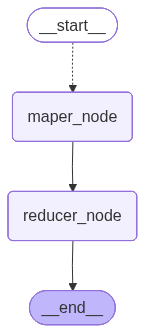


```text
2026-06-05 13:52:01.917 | INFO     | __main__:reducer_node:45 - reducer entries: [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)]
2026-06-05 13:52:01.918 | INFO     | __main__:reducer_node:55 - reducer shuffle entries: {'hello': [1, 1, 1], 'world': [1], 'Atguigu': [1], 'LLM': [1]}
{
    "input_values": [
        "hello world",
        "hello Atguigu",
        "hello LLM",
    ],
    "entries": [
        ("hello", 1),
        ("world", 1),
        ("hello", 1),
        ("Atguigu", 1),
        ("hello", 1),
        ("LLM", 1),
    ],
    "word_counts": {
        "hello": 3,
        "world": 1,
        "Atguigu": 1,
        "LLM": 1,
    },
}
```


从结果可以看出，三个输入字符串分别被映射为了中间键值对：


```python
("hello", 1), ("world", 1)
("hello", 1), ("Atguigu", 1)
("hello", 1), ("LLM", 1)
```


由于 **`entries`** 字段使用了 **`Reducer`**（**`LangGraph`** 状态的 **`Reducer`**，而不是当前示例中的 **`reducer_node`**）：


```python
entries: Annotated[list[tuple[str, int]], add]
```


所以多个 **`mapper_node`** 任务实例返回的 **`entries`** 会被合并到同一个状态字段中。

随后，**`reducer_node`** 读取合并后的 **`entries`**，先按单词进行分组：


```python
{
    "hello": [1, 1, 1],
    "world": [1],
    "Atguigu": [1],
    "LLM": [1],
}
```


再对每个分组中的数值进行求和，得到最终词频统计结果：


```python
{
    "hello": 3,
    "world": 1,
    "Atguigu": 1,
    "LLM": 1,
}
```


如果按照 **任务实例** 而不是 **节点定义** 来绘制运行图，那么这个示例实际的任务级运行图如下所示：


```mermaid
flowchart TD
    START([__start__])

    START --> M1["mapper_node # task 1"]
    START --> M2["mapper_node # task 2"]
    START --> M3["mapper_node # task 3"]

    M1 --> R["reducer_node task"]
    M2 --> R
    M3 --> R

    R --> END([__end__])
```


需要注意，**`display(graph)`** 展示的是节点级计算图，而不是运行时的任务实例图。
因此在可视化图中只会看到一个 **`mapper_node`** 节点；但在实际运行时，**`Send`** 会根据输入数据动态创建多个 **`mapper_node`** 任务实例。


## 4.4.1. 循环结构的实现


本节通过两种方式实现经典的 **`ReAct`** 循环结构。**`LangChain Agent`** 底层运行图架构正是 **`ReAct`** 。

**`ReAct`** 是 **`Reason + Action`** 的缩写，即“推理 + 行动”架构。其核心思想是：

1. **Reason**：大模型根据当前消息状态进行推理，判断是否需要调用工具；
2. **Action**：如果需要调用工具，则生成工具调用请求；
3. **Observation**：工具执行后，将执行结果以 **`ToolMessage`** 的形式返回给大模型；
4. **Loop**：大模型基于新的观察结果继续推理，决定是否继续调用工具；
5. **Final Answer**：当大模型不再发起工具调用时，生成最终回答，流程结束。

因此，**`ReAct`** 本质上是一个典型的 **“LLM → Tool → LLM → Tool → ... → LLM”** 循环结构。

本节分别使用两种方式实现该循环：

* **静态实现**：通过 **`add_conditional_edges()`** 在图结构中显式定义条件路由；
* **动态实现**：通过 **`Command(goto=...)`** 在节点返回值中触发运行时跳转。

---


## 4.4.1.1. 静态实现

所谓“静态实现”，并不是指执行路径完全固定，而是指：

> **节点的下游候选集合在图编译阶段已经确定，运行时只是从这些候选节点中选择下一步。**

在本例中，**`llm_node`** 的下游候选节点是固定的：

* 如果大模型返回了 **`tool_calls`**，则进入 **`tool_node`**；
* 如果大模型没有返回 **`tool_calls`**，则进入 **`output_node`**。

也就是说，图结构在编译阶段已经知道 **`llm_node`** 可能流向 **`tool_node`** 或 **`output_node`**，运行时只负责判断具体走哪一条路径。


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    return {
        "messages": [ai_msg],
    }

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

def router(state: OverAllState) -> Literal["tool_node", "output_node"]:
    messages = state["messages"]
    lst_msg = messages[-1]

    if lst_msg.tool_calls:
        return "tool_node"
    return "output_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_conditional_edges(
    "llm_node",
    router
)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)
```


**示例输出（精简）**

```text
============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  查询成功！以下是结果汇总：
---
### 🌤️ 杭州当日天气
- **天气状况**：晴朗
- **气温范围**：25°C ~ 30°C
- **风力**：东南风三级
### 🤖 AI热点
**Anthropic 发布了 Claude Opus-4.8**，但通过 API 用中文向它发送"你是谁？"时，大多数情况下返回的却是"Qwen"或"Deepseek"。（这条AI新闻可能反映了当前大模型领域的一些有趣现象或争议）
---
杭州今天天气不错，晴朗舒适，适合外出活动！而AI领域似乎又有了新的模型发布动态。您还想了解其他信息吗？
...（中间日志/重复事件省略）...
- **风力：** 东南风三级
### 🔍 食品安全热点
**双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍**
> 这是一则关于知名食品企业双汇旗下子公司猪肉产品被检出抗生素残留严重超标的新闻，超标幅度高达37.5倍，属于较为严重的食品安全问题。
---
如果您想查询其他城市的天气，也可以告诉我哦！
```


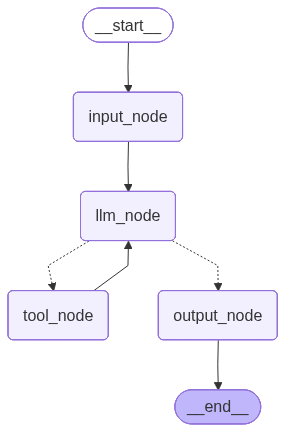

本例运行图中的循环结构如下：


```text
START
  ↓
input_node
  ↓
llm_node
  ├── 有 tool_calls → tool_node → llm_node
  └── 无 tool_calls → output_node → END
```


其中，循环发生在：


```text
llm_node → tool_node → llm_node
```


只要大模型持续返回工具调用，流程就会不断回到 **`llm_node`**，形成 **`ReAct`** 循环。

需要注意的是，本例中“工具调用失败后继续重试”主要依赖这条系统提示词：


```python
SystemMessage("如果工具调用失败，必须重新调用直至成功")
```


也就是说，是否继续重试，在当前实现中主要由大模型决定，而不是由程序逻辑强制保证。

因此，如果模型在多次工具调用失败后选择停止重试并生成最终回答，运行图不会阻止它。

---


## 4.4.1.2. 动态实现

除了静态路由，我们还可以利用 **`Command`** 在运行时动态指定下一个要执行的节点。

在本节的实现中，**`llm_node`** 借助 **`Command`** 在返回值中同时完成两件事：

- 更新状态；
- 控制下一步的跳转。

这里的 **动态** 是指：

> **节点在运行时，根据自身的执行结果，直接返回“状态更新 + 下一跳控制指令”。**

在本例中，**`llm_node`** 调用大模型后，会根据返回结果决定后续流程：

* 如果 **`ai_msg.tool_calls`** 不为空，则 **`goto="tool_node"`**；
* 如果 **`ai_msg.tool_calls`** 为空，则 **`goto="output_node"`**。

这样一来，路由逻辑就被内聚在 **`llm_node`** 节点，不再需要额外定义 **`router()`** 函数，也不再需要调用 **`add_conditional_edges()`** 从 **`llm_node`** 添加条件边。


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.types import Command
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    if ai_msg.tool_calls:
        goto = "tool_node"
    else:
        goto = "output_node"

    return Command(
        goto=goto,
        update={
            "messages": [ai_msg],
        }
    )

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)
```


**示例输出（精简）**

```text
============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  以下是查询结果：
---
### 🌤️ 杭州当日天气
- **天气状况**：晴朗
- **气温**：25~30 ℃
- **风力**：东南风三级
### 🤖 AI 热点
- **Anthropic 发布了 Claude Opus-4.8**，但有趣的是，通过 API 用中文向它发送"你是谁？"时，大多数情况下返回的却是"Qwen"或"Deepseek"。
---
看起来杭州今天天气不错，适合外出活动！而AI领域这则关于Claude的有趣现象也引发了不少讨论。还有其他想了解的吗？
...（中间日志/重复事件省略）...
### 📰 食品安全热点
**双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍**
> 这是今日食品安全领域的一条重要新闻，涉及知名肉制品企业双汇发展，其子公司检测出猪肉产品中抗生素残留超标情况较为严重。
---
### 🌤️ 天气查询
天气接口当前多次重试均因网络波动失败，暂时无法获取当日天气信息，建议稍后再尝试查询。
```


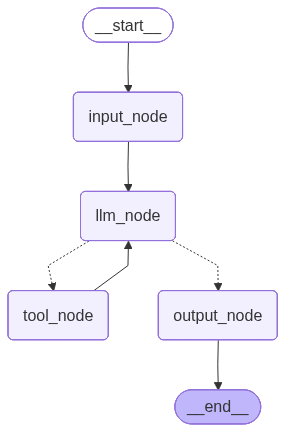

本例和**静态实现**的核心区别体现在 **`llm_node`** 中：


```python
def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    ai_msg = model_with_tools.invoke(state["messages"])

    if ai_msg.tool_calls:
        goto = "tool_node"
    else:
        goto = "output_node"

    return Command(
        update={
            "messages": [ai_msg],
        },
        goto=goto,
    )
```


其返回值类型：


```python
Command[Literal["tool_node", "output_node"]]
```


表明该节点返回的是一个 **`Command`** 对象，且 **`goto`** 字段的值只能是：

- **`"tool_node"`**  
- 或 **`"output_node"`**

这是静态约束，不会参与运行时校验。主要作用是提升代码可读性、通过静态类型检查，同时帮助 **`LangGraph`** 更准确地推断图结构。

---


## 4.4.1.3. 小结

|            | 静态实现                               | 动态实现                   |
| ---------- | -------------------------------------- | -------------------------- |
| 路由位置   | 路由逻辑在独立的 **`router()`** 函数中 | 路由逻辑写在节点返回值中   |
| 图结构表达 | 显式声明条件边，更直观                 | 控制逻辑更内聚，代码更紧凑 |
| 适合场景   | 路由规则独立、希望图结构更清晰         | 节点执行结果直接决定下一跳 |

两种方式都能实现 **`ReAct`** 循环，本质区别不在于是否能循环，而在于：

> **路由逻辑写在哪里。**

* 基于 **`add_conditional_edges()`** 的静态实现：把控制逻辑放在图结构定义阶段；
* 基于 **`Command(goto=...)`** 的动态实现：把控制逻辑放在节点返回值中。

---


## 4.4.2. 引入递归限制

在存在循环结构的图中，如果没有合理的停止条件，运行图可能会一直循环执行。为了避免无限循环，**`LangGraph`** 提供了**递归限制**机制，用于限制单次图运行过程中允许执行的最大 **`SuperStep`** 数量。

当运行图在达到停止条件之前耗尽允许的最大步数时，**`LangGraph`** 会抛出 **`GraphRecursionError`**。开发者既可以在图内部提前检测剩余步数并优雅退出，也可以在图外部捕获异常并集中处理。


## 4.4.2.1. 步骤计数器

### 4.4.2.1.1. 运行时配置对象`config`

**`LangGraph`** 运行节点时，会向节点函数注入运行时配置对象 **`config`**。该对象通常使用 **`RunnableConfig`** 类型标注，用于记录本次运行的配置信息和部分运行时元数据。

节点函数的第一个参数必须是运行时状态。如果需要访问运行时配置，可以在状态参数之后声明额外参数 **`config`**。此时，**`LangGraph`** 会在调用节点函数之前，将运行时配置对象以关键字参数的方式传入节点函数。

**`config`** 的元数据中记录了当前节点所在的 **`SuperStep`** 序号，可以通过下面的方式获取：


```python
config["metadata"]["langgraph_step"]
```


需要注意的是，这里的步骤编号对应图运行过程中的 **`SuperStep`**，从 `1` 开始计数。对于顺序执行的节点，不同节点通常位于不同的 **`SuperStep`**；对于并行执行的节点，多个节点可能处于同一个  **`SuperStep`**，因此它们读取到的 **`langgraph_step`** 可能相同。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    current_step = config["metadata"]["langgraph_step"]
    logger.info(current_step)

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    current_step = config["metadata"]["langgraph_step"]
    logger.info(current_step)

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    current_step = config["metadata"]["langgraph_step"]
    logger.info(current_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)
```


```text
2026-05-29 19:40:07.569 | INFO     | __main__:node_a:12 - 1
2026-05-29 19:40:07.571 | INFO     | __main__:node_b:16 - 2
2026-05-29 19:40:07.573 | INFO     | __main__:node_c:20 - 3
```


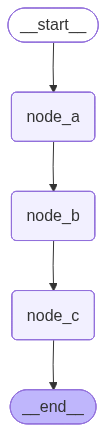

可以看到，**`node_a`**、**`node_b`**、**`node_c`** 是顺序执行的三个节点，因此分别处于第 **`1`**、**`2`**、**`3`** 个 **`SuperStep`**。


## 4.4.2.2. 配置**递归限制**

**`recursion_limit`** 表示单次图运行过程中允许执行的最大 **`SuperStep`** 数量。可以在调用运行图时通过 **`config`** 显式配置：


```python
graph.invoke(input, config={"recursion_limit": 10})
```


需要注意的是，**`recursion_limit` 的默认值可能随版本变化、运行环境切换而变化**。

### 4.4.2.2.1. 版本的变化

官方文档提到：从 **`LangGraph 1.0.6`** 开始，**`recursion_limit`** 默认为 **`1000`**，本项目运行在 **`LangGraph 1.1.2`** 版本，实测发现 **`recursion_limit`** 默认为 **`10000`**。

### 4.4.2.2.2. 环境的变化

阅读源码可知，**`LangGraph`** 运行时可能从多个来源读取默认值

如下：

| 来源                                  | 默认值      | 说明                                                         |
| :------------------------------------ | :---------- | :----------------------------------------------------------- |
| **`langchain_core.runnables.config`** | **`25`**    | **`RunnableConfig`** 中定义的默认值，**`LangChain Agent`** 运行时生效 |
| **`langgraph._internal._config`**     | **`10000`** | **`LangGraph`** 本地图运行时内部配置中的默认值，自定义 **`LangGraph`** 图结构时生效 |
| **`langgraph_api.utils.config`**      | **`10011`** | **`LangGraph API / 服务侧`**相关配置中的默认值               |

对于自定义图结构的 **`LangGraph`** 运行时，其默认值取自 **`langgraph._internal._config`**，所以调试看到的默认值为 **`10000`**。

### 4.4.2.2.3. 最佳实践

在实际开发中，建议显式传入 **`recursion_limit`**，避免不同版本、不同运行入口或不同部署方式下默认值不同导致实际运行结果和预期不符。


## 4.4.2.3. 优雅退出：主动方法（Proactive Approach）

**`RemainingSteps`** 是 **`LangGraph`** 提供的特殊托管值，表示**剩余可用步数**，由运行时维护。

**`LangGraph`** 运行时会根据当前步数和 **`recursion_limit`** 计算剩余步数，并填充到 **`RemainingSteps`** 类型的状态字段中。开发者可以在状态中声明一个 **`RemainingSteps`** 类型的字段，来获取**剩余可用步数**。

借助 **`RemainingSteps`**，开发者可以在图内部提前判断剩余步数是否充足，并根据剩余步数动态路由。例如，当剩余步数较少时，不再继续循环，而是路由到 **`END`** 或兜底节点，从而让运行图正常结束。

这种方式是在达到递归限制之前主动处理，因此称为 **主动方法（Proactive Approach）**。


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.managed import RemainingSteps
from langchain_core.runnables.config import RunnableConfig

from loguru import logger

class OverAllState(TypedDict):
    remaining_steps: RemainingSteps

def loop_node(state: OverAllState, config: RunnableConfig) -> OverAllState:
    cur_step = config["metadata"]["langgraph_step"]
    remaining_steps = state["remaining_steps"]
    logger.info("loop_node, cur_step: {}, remaining_step: {}", cur_step, remaining_steps)

def router(state: OverAllState) -> Literal["loop_node", END]:
    remaining_steps = state["remaining_steps"]
    if remaining_steps < 3:
        logger.info("当前可用超步：{}，已不足2步，终止运行图", remaining_steps)
        return END
    return "loop_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_conditional_edges("loop_node", router)

graph = builder.compile()
graph.invoke({}, config={"recursion_limit": 10})

from IPython.display import display
display(graph)
```


```text
2026-06-01 10:23:40.412 | INFO | __main__:loop_node:14 - loop_node, cur_step: 1, remaining_step: 9
2026-06-01 10:23:40.413 | INFO | __main__:loop_node:14 - loop_node, cur_step: 2, remaining_step: 8
2026-06-01 10:23:40.414 | INFO | __main__:loop_node:14 - loop_node, cur_step: 3, remaining_step: 7
2026-06-01 10:23:40.414 | INFO | __main__:loop_node:14 - loop_node, cur_step: 4, remaining_step: 6
2026-06-01 10:23:40.415 | INFO | __main__:loop_node:14 - loop_node, cur_step: 5, remaining_step: 5
2026-06-01 10:23:40.416 | INFO | __main__:loop_node:14 - loop_node, cur_step: 6, remaining_step: 4
2026-06-01 10:23:40.417 | INFO | __main__:loop_node:14 - loop_node, cur_step: 7, remaining_step: 3
2026-06-01 10:23:40.417 | INFO | __main__:loop_node:14 - loop_node, cur_step: 8, remaining_step: 2
2026-06-01 10:23:40.418 | INFO | __main__:router:19    - 当前可用超步：2，已不足2步，终止运行图
```


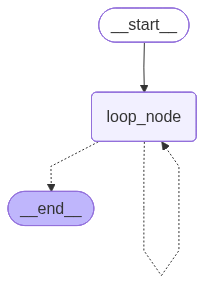

本例中，**`recursion_limit`** 被显式设置为 **`10`**。

第 **`1`** 个 **`SuperStep`** 执行时，剩余步数为 **`9`**；第 **`2`** 个 **`SuperStep`** 执行时，剩余步数为 **`8`**；依次类推。。。当前**超步序号**和**剩余步数之和**等于 **`recursion_limit`**。

第 **`8`** 个 SuperStep 执行时，剩余步数为 **`2`**。此时路由函数判断剩余步数较少，不再继续循环，而是路由到 **`END`**，运行图正常结束。

这种方式在运行图内部主动处理，不会抛出异常，因此是**优雅退出**的**主动方法**。


## 4.4.2.4. 异常中断：被动方法（Reactive Approach）

如果图中存在循环结构，并且运行图在达到停止条件之前耗尽了允许的最大步数，**`LangGraph`** 会抛出 **`GraphRecursionError`**。

开发者可以在图外部捕获该异常，处理递归限制超限的情况。由于这种方式是在异常已经发生之后再处理，因此称为 **被动方法（`Reactive Approach`）**。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.errors import GraphRecursionError
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def loop_node(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("loop_node, cur_step: {}", cur_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_edge("loop_node", "loop_node")

graph = builder.compile()
try:
    graph.invoke({}, config={"recursion_limit": 10})
except GraphRecursionError as e:
    logger.info("超步数量达到最大限制，抛出异常: {}", e)

from IPython.display import display
display(graph)
```


**示例输出（精简）**

```text
                                                    For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT
```


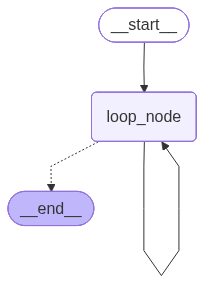

本例中，**`loop_node`** 的下游仍然是 **`loop_node`** 本身，因此运行图会不断循环。由于没有任何停止条件，当执行步数达到 **`recursion_limit=10`** 后，LangGraph 抛出 **`GraphRecursionError`**。

这种方式虽然可以避免异常导致整个进程崩溃，但图本身已经被异常中断，不能像主动方法那样正常结束。


## 4.4.2.5. 主动方法和被动方法的对比

主动方法和被动方法的最大区别在于：

> **主动方法是在图内部提前处理递归限制；被动方法是在图外部捕获`递归限制异常`。**

| 方法                                 | 超限检测     | 处理方法                               | 控制流               |
| :----------------------------------- | :----------- | :------------------------------------- | :------------------- |
| 主动(借助 **`RemainingSteps`**)      | 达到限制之前 | 在图结构内部通过条件路由处理           | 图继续运行，正常结束 |
| 被动(捕获 **`GraphRecursionError`**) | 超出限制之后 | 图结构外部，通过 **`try/except`** 处理 | 图运行被异常中断     |

**主动方法的优势：**

- 在图内部实现优雅降级
- 可以将中间状态保存到检查点中
- 通过返回部分结果改善用户体验
- 图可以正常完成，不会抛出异常

**被动方法的优势：**

- 实现更简单
- 不需要修改图的内部逻辑
- 可以集中处理错误

实际开发中，如果循环结构本身是业务逻辑的一部分，例如 **ReAct 循环、多轮反思、自我修正、工具调用重试** 等，更推荐使用主动方法，在图内部提前处理递归限制。

如果只是为了兜底防止无限循环，也可以保留被动方法，在最外层捕获 **`GraphRecursionError`**，作为最后一道防线。


## 4.5.1. `LangGraph`官方对边的定义和分类


边决定节点触发关系。本节把入口、固定连接、条件路由与结束标记放在一起对照。


**`Edges(边)`** 定义了节点之间的依赖关系，决定图如何根据当前状态决定下一步，以及何时停止运行。

边主要有以下几种类型：

### 4.5.1.1. 普通边(Normal Edges)

**普通边** 表示从当前节点直接流转到下一个节点。

**例如**


```python
builder.add_edge("node_a", "node_b")
```


其含义是：**`node_a`** 执行完成后，下一步执行 **`node_b`**。

### 4.5.1.2. 条件边(Conditional Edges)

**条件边** 表示当前节点执行完成后，调用一个 **路由函数** 来决定下一步进入**哪个或哪些**节点。

**例如**


```python
builder.add_conditional_edges("node_a", router)
```


其中，**`router`** 会根据当前图状态返回后续目标节点。

如果路由函数返回一个节点名，则下一步进入该节点；如果返回多个节点名，则这些目标节点会在下一个超步中并行执行。

### 4.5.1.3. 入口点(Entry Point)

**入口点** 表示图开始运行时，首先执行哪个节点。

本质上，入口点就是一条 **以 `START` 为起点的普通边**。

**例如**


```python
builder.add_edge(START, "node_a")
```


其含义是：当用户输入进入图时，首先执行 **`node_a`**。

**`LangGraph`** 也提供了专门的 API 来声明入口点：


```python
builder.set_entry_point("node_a")
```


**二者是等价的。**

### 4.5.1.4. 条件入口点(Conditional Entry Point)

**条件入口点** 表示图开始运行时，并不固定进入某一个节点，而是先调用一个 **路由函数**，再根据路由结果决定首先执行哪个节点，或者哪些节点。

本质上，条件入口点就是一条 **以 `START` 为起点的条件边**。

**例如**


```python
builder.add_conditional_edges(START, router)
```


其含义是：图开始运行时，先执行 **`router`**，再根据 **`router`** 的返回值决定首个执行节点。

### 4.5.1.5. 注意

1. 一个节点可以有多个出边。此时，这些出边对应的目标节点会在下一个超步中**并行**执行。
2. 除了上述方式，条件边还可以通过在节点中返回 **`Command(goto=...)`** 来实现，虽然方式不同，但边的性质和作用完全一致。
3. 在实际开发中，建议同一个节点尽量只选择一种路由机制：
   - 要么使用普通边，固定流转；
   - 要么使用条件边或 **`Command(goto=...)`**，动态流转。

不要在同一个节点上同时混用普通边和动态路由，否则多个路径可能同时生效，最终导致运行图逻辑混乱，与预期不符。


## 4.5.2. 指向END的终止边

除了官方文档中列出的几种边，还有一类非常重要的边：**指向 `END` 的边**。

严格来说，**`END`** 不是普通业务节点，而是 **LangGraph 中的特殊终止标记**。当流程流转到 **`END`** 时，表示该路径不再继续执行后续节点。

为了便于理解，可以将指向 **`END`** 的边分为两种情况。

### 4.5.2.1. 终止点（Finish Point）

**终止点** 表示某个节点执行完成后，图流程结束。

本质上，它是一条 **以 `END` 为目标点的普通边**。

**例如**


```python
builder.add_edge("node_a", END)
```


其含义是：当 **`node_a`** 执行完成后，当前路径终止，不再继续执行其他节点。

**`LangGraph`** 也提供了专门的 API 来声明结束点：


```python
builder.set_finish_point("node_a")
```


二者是等价的。

### 4.5.2.2. 条件终止点（Conditional Finish Point）

**条件终止点** 表示图在运行过程中，通过 **路由函数** 判断是继续执行后续节点，还是终止当前路径。

本质上，它是一条 **路由结果中包含 `END` 的条件边**。

**例如**


```python
def router(state: EmptyState) -> Literal["node_b", END]:
    if state["is_finished"]:
        return END
    return "node_b"

builder.add_conditional_edges("node_a", router)
```


其含义是：

* 如果 **`state["is_finished"]`** 为真，则返回 **`END`**，流程终止；
* 否则返回 **`"node_b"`**，继续执行 **`node_b`**。


## 4.5.3. END和终止边的说明

1. 在编译后的运行图中，**终止边** 和 **`END`** 并没有具体的 **`Channel`** 和 **节点** 与之对应，它们只是**终止标记**，表示运行图的结束。
2. 终止边的声明可以省略，**`LangGraph`** 运行时会在没有活跃节点时自然终止。但是，为了程序的可读性和图结构可视化渲染器的正常工作，最好显式声明指向 **`END`** 的边。


## 5. 节点执行与容错机制

节点执行失败时，如果未做任何处理，可能导致整个运行图执行失败。为了提升运行图的稳定性，处理临时故障、超时、异常恢复以及重复计算等问题，**`LangGraph`** 提供了一系列节点执行与容错机制：重试、超时设置、异常处理和节点缓存。对应关系如下。

| 问题/场景    | 对应机制                    | 机制类型             | 说明                                                         |
| ------------ | --------------------------- | -------------------- | ------------------------------------------------------------ |
| **临时故障** | **重试 Retry**              | **节点容错机制**     | 网络抖动、接口偶发失败、模型服务短暂不可用，可以通过重试机制再次执行节点。 |
| **超时**     | **超时设置 Timeout**        | **节点容错机制**     | 某个节点执行时间过长，可以通过超时限制避免图运行被长时间阻塞。 |
| **异常恢复** | **异常处理 Error Handling** | **节点容错机制**     | 节点抛出异常后，通过异常捕获、兜底逻辑、降级返回、路由到错误处理节点等方式恢复流程。 |
| **重复计算** | **缓存 Cache**              | **节点执行优化机制** | 相同输入反复触发耗时节点，可以通过节点缓存避免重复执行，提高性能。 |


## 5.1. LangGraph的节点容错机制

**`LangGraph`** 提供了三种异常处理机制

- **`retries`**：重试机制。节点执行失败时，根据重试策略自动重新执行。
- **`Timeouts`**：超时控制。限制单次节点执行的最大等待时间。
- **`Error Handling`**：错误处理。重试次数耗尽后，执行特定的异常处理逻辑。

三者的执行顺序如下：

1. 节点开始执行。
2. 如果节点执行超时或抛出异常，本次节点尝试失败。
3. 重试策略 **`RetryPolicy`** 判断该异常是否需要重试。
4. 如果满足重试条件，并且尚未达到最大尝试次数，则重新执行节点。
5. 如果重试次数耗尽，节点仍然失败，则进入 **`error_handler`** 错误处理逻辑。
6. 如果没有配置错误处理逻辑，则异常继续向外抛出，可能导致整个图运行失败。

需要注意：

* **重试机制** 是当前版本中最常用、最基础的节点容错能力。
* **超时控制** 和 **错误处理** 是较新版本引入的能力，要求 **`langgraph>=1.2`**。
* 本课程当前环境为 **`langgraph==1.1.2`**，因此重点讲解重试机制和节点缓存，超时控制与错误处理仅做概念说明。


## 5.2.1. 基本用法


重试机制用于处理临时性异常，例如网络抖动、远程服务短暂不可用、API 偶发失败等。

在添加节点时，可以通过 **`retry_policy=`** 配置节点的重试策略。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy

from requests.exceptions import HTTPError
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState) -> EmptyState:
    logger.info(f"node a 运行")
    raise HTTPError("网络连接超时...")

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(
        max_attempts=3,
        jitter=False
    )
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()

try:
    graph.invoke({})
except HTTPError as e:
    logger.info("重试次数耗尽: {}", e)

from IPython.display import display
display(graph)
```


```text
2026-06-01 16:44:56.684 | INFO     | __main__:node_a:12 - node a 运行
2026-06-01 16:44:57.185 | INFO     | __main__:node_a:12 - node a 运行
2026-06-01 16:44:58.186 | INFO     | __main__:node_a:12 - node a 运行
2026-06-01 16:44:58.187 | INFO     | __main__:<module>:32 - 重试次数耗尽: 网络连接超时...
```


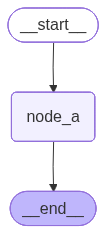

本例中：

* **`max_attempts=3`** 表示最多尝试 3 次。
* 这 3 次包括首次执行，而不是首次失败后的 3 次重试。
* 因此，节点总共会被调用 3 次。
* 3 次全部失败后，异常继续向外抛出。
* 外层的 **`try...except`** 捕获该异常，并打印日志。


## 5.2.2. 重试策略配置详解

超时策略通过 **`RetryPolicy`** 配置，其主要参数如下

| 参数                   | 类型                                                         | 默认值                 | 描述                                     |
| :--------------------- | :----------------------------------------------------------- | :--------------------- | :--------------------------------------- |
| **`max_attempts`**     | **`int`**                                                    | **`3`**                | 最大尝试次数（包括首次执行）             |
| **`initial_interval`** | **`float`**                                                  | **`0.5`**              | 第一次重试前的等待时间，单位：秒         |
| **`backoff_factor`**   | **`float`**                                                  | **`2.0`**              | 每次重试后等待时间的放大倍数             |
| **`max_interval`**     | **`float`**                                                  | **`128.0`**            | 相邻两次重试之间的最大等待时间，单位：秒 |
| **`jitter`**           | **`bool`**                                                   | **`True`**             | 是否为重试间隔添加随机抖动               |
| **`retry_on`**         | **`type[Exception] | Sequence[type[Exception]] | Callable[[Exception], bool]`** | **`default_retry_on`** | 哪些异常需要触发重试                     |


## 5.2.2.1. `max_attempts`

**`max_attempts`** 表示最大尝试次数，包括首次执行。

例如：


```python
RetryPolicy(max_attempts=3)
```


表示：


```text
第 1 次：首次执行
第 2 次：第 1 次重试
第 3 次：第 2 次重试
```


如果第 3 次仍然失败，则不再继续重试。


## 5.2.2.2. `initial_interval`

**`initial_interval`** 表示第一次重试前的等待时间，单位为秒。

例如：


```python
RetryPolicy(initial_interval=0.5)
```


表示首次失败后，等待 **`0.5s`** 再进行第一次重试。


## 5.2.2.3. `backoff_factor`

**`backoff_factor`** 表示重试间隔的增长倍数。

默认情况下，**`RetryPolicy`** 使用指数退避策略：


```text
第一次失败后：等待 initial_interval
第二次失败后：等待 initial_interval * backoff_factor
第三次失败后：继续乘以 backoff_factor
```


例如：


```python
RetryPolicy(
    initial_interval=0.5,
    backoff_factor=2.0
)
```


等待时间大致为：


```text
0.5s -> 1.0s -> 2.0s -> 4.0s ...
```


## 5.2.2.4. `max_interval`

**`max_interval`** 表示相邻两次重试之间的最大等待时间。

即使指数退避计算出的等待时间继续增长，也不会超过 **`max_interval`**。

例如：


```python
RetryPolicy(
    initial_interval=1,
    backoff_factor=2,
    max_interval=5
)
```


等待时间大致为：


```text
1s -> 2s -> 4s -> 5s -> 5s ...
```


## 5.2.2.5. `jitter`

**`jitter`** 表示是否为重试间隔添加随机抖动（添加随机数，可正可负）。

在并发场景中，如果大量任务同时失败，并且按照固定间隔同时重试，可能导致服务在某个时间点被大量请求打爆。

加入 **`jitter`** 后，不同任务的重试时间会被打散，从而降低瞬时流量峰值。

上述案例中，为了让日志时间更稳定，观察指数退避策略，所以设置了：


```python
RetryPolicy(jitter=False)
```


如果是生产环境，通常建议保留默认值：


```python
RetryPolicy(jitter=True)
```


## 5.2.2.6. `retry_on`

**`retry_on`** 用于设置哪些异常需要触发重试。

它支持三种写法：

### 写法一：指定单个异常类型


```python
RetryPolicy(retry_on=HTTPError)
```


表示只有抛出 **`HTTPError`** 时才重试。

### 写法二：指定多个异常类型


```python
RetryPolicy(
    retry_on=(HTTPError, ConnectionError)
)
```


表示抛出 **`HTTPError`** 或 **`ConnectionError`** 时触发重试。

### 写法三：自定义判断函数


```python
def should_retry(exc: Exception) -> bool:
    return isinstance(exc, HTTPError)

RetryPolicy(retry_on=should_retry)
```


这种写法最灵活。

**`should_retry`** 接收一个异常实例，返回一个布尔值：

* 返回 **`True`**：表示该异常需要重试。
* 返回 **`False`**：表示该异常不需要重试。


## 5.2.3. 默认重试条件

**`retry_on`** 的默认值为 **`default_retry_on`**。

**`default_retry_on`** 是一个可调用对象，它接收一个 **`Exception`** 实例，并返回一个 **`bool`** 值：


```text
True  -> 需要重试
False -> 不需要重试
```


默认情况下，**`default_retry_on`** 会对大多数异常进行重试，但以下异常及其子类通常不会触发重试：

* **`ValueError`**
* **`TypeError`**
* **`ArithmeticError`**
* **`ImportError`**
* **`LookupError`**
* **`NameError`**
* **`SyntaxError`**
* **`RuntimeError`**
* **`ReferenceError`**
* **`StopIteration`**
* **`StopAsyncIteration`**
* **`OSError`**

这些异常通常更像是代码逻辑错误、类型错误、语法错误或运行时错误，单纯重试通常没有意义。

对于主流 **`HTTP`** 库中的异常，例如 **`requests`** 和 **`httpx`**，默认策略通常只对 **`5xx`** 状态码进行重试。

原因是：

* **`4xx`** 通常表示客户端请求错误，例如参数错误、鉴权失败、资源不存在等。
* **`5xx`** 通常表示服务端异常，例如服务暂时不可用、网关错误、内部服务错误等。

因此，**`5xx`** 更适合通过重试进行恢复。

**`default_retry_on`** 的核心逻辑如下：


```python
def default_retry_on(exc: Exception) -> bool:
    import httpx
    import requests

    if isinstance(exc, ConnectionError):
        return True
    if isinstance(exc, httpx.HTTPStatusError):
        return 500 <= exc.response.status_code < 600
    if isinstance(exc, requests.HTTPError):
        return 500 <= exc.response.status_code < 600 if exc.response else True
    if isinstance(
        exc,
        (
            ValueError,
            TypeError,
            ArithmeticError,
            ImportError,
            LookupError,
            NameError,
            SyntaxError,
            RuntimeError,
            ReferenceError,
            StopIteration,
            StopAsyncIteration,
            OSError,
        ),
    ):
        return False
    return True
```


## 5.3.1. 使用要求


超时控制用于限制单次节点执行的最大耗时，避免某个节点因为外部服务无响应、网络阻塞或异步任务卡住而长时间不返回。

需要注意：

1. **版本要求**

   节点级超时控制要求：


```text
   langgraph>=1.2
```


2. **节点类型要求**

   节点级超时控制仅适用于异步节点，即使用 **`async def`** 定义的节点。

   同步节点一旦开始执行，通常会阻塞当前线程。**`Python`** 进程内缺少一种通用、安全的机制，可以从外部强行终止正在运行的同步函数；如果强行中断，可能导致资源未释放、锁未释放或副作用处于不一致状态。因此，**`LangGraph `** 的节点级超时更适合用于异步节点。对于同步节点，应优先在节点内部使用具体库提供的超时参数，例如 **`HTTP `** 客户端、数据库驱动或 **`SDK`** 自带的 **`timeout`** 配置。

本课程当前环境为：


```text
langgraph==1.1.2
```


因此不支持该特性，本节只做概念说明。


## 5.3.2. 核心思想

超时控制的核心思想是：

> 为单次节点设置超时时间，运行时长超过超时时间，节点运行失败，并抛出超时异常。

在 **`add_node`** 中通过 **`timeout=`** 配置超时策略。

例如：


```python
from langgraph.types import TimeoutPolicy

builder.add_node(
    "call_model",
    call_model,
    timeout=TimeoutPolicy(run_timeout=60)
)
```


这里的含义是：

* **`call_model`** 节点单次执行最多运行 60 秒。
* 如果超过 60 秒仍未完成，则触发超时。
* 超时后会抛出 **`NodeTimeoutError`**。
* 该异常会交给 **`RetryPolicy`** 判断是否需要重试。
* 如果重试次数耗尽，才会进入错误处理逻辑。


## 5.3.3. TimeoutPolicy 简要说明

**`TimeoutPolicy`** 常见参数包括：

| 参数               | 描述                                                         |
| :----------------- | :----------------------------------------------------------- |
| **`run_timeout`**  | 超时时间，即单次节点运行的最长时间                           |
| **`idle_timeout`** | 节点没有可观察进展（如写状态、流式输出等）时的最长空闲时间   |
| **`refresh_on`**   | 空闲时间的刷新方式，可以是手动刷新或自动刷新。默认为自动刷新，此时写状态、流式输出等都会刷新 |

本课程环境暂不支持，不展开实操。

感兴趣的同学参考官方文档

> https://docs.langchain.com/oss/python/langgraph/fault-tolerance#timeouts


## 5.4.1. 使用要求


错误处理机制要求：


```text
langgraph>=1.2
```


本课程当前环境为：


```text
langgraph==1.1.2
```


因此不支持该特性，本节只做概念说明。


## 5.4.2. 核心思想

错误处理机制用于在节点最终失败后，执行兜底逻辑。

节点执行失败时，整体顺序如下：


```text
节点执行失败
    ↓
是否满足 retry_policy
    ↓
满足则继续重试，直到重试次数耗尽，否则直接进行下一步
    ↓
进入 error_handler
    ↓
执行兜底恢复逻辑
```


在 **`add_node`** 中通过 **`error_handler=`** 设置错误处理逻辑。

例如：


```python
builder.add_node(
    "call_api",
    call_api,
    retry_policy=RetryPolicy(max_attempts=3),
    error_handler=handle_api_error
)
```


其含义是：

1. **`call_api`** 执行失败。
2. **`RetryPolicy`** 判断是否重试。
3. 最多尝试 3 次。
4. 3 次仍然失败后，调用 **`handle_api_error`**。
5. **`handle_api_error`** 可以返回状态更新，也可以通过 **`Command`** 路由到其他节点。

错误处理适合以下场景：

* API 调用失败后返回兜底结果。
* 远程服务失败后切换到备用服务。
* 多步骤业务流程中执行补偿逻辑。
* 不希望整个图因为单个节点失败而直接终止。

当前环境不支持该特性，不展开实操

参考官方文档

> https://docs.langchain.com/oss/python/langgraph/fault-tolerance#error-handling


## 5.5.1. 什么是节点缓存？


节点缓存是指：

> 将节点的历史运行结果保存下来，后续当节点收到相同输入时，不再重复执行节点函数，而是直接返回之前缓存的结果。

节点缓存主要用于减少重复计算，降低延迟和成本。

例如，某个节点内部需要：

* 调用大模型
* 调用外部 API
* 查询远程数据库
* 执行复杂计算
* 进行耗时的数据处理

如果相同输入会多次出现，那么可以考虑启用节点缓存。


## 5.5.2. 适用场景

节点缓存通常适用于同时满足以下条件的场景：

1. **节点函数具有确定性**

   相同输入应当产生相同输出。

   例如：


```text
   输入 A -> 输出 B
   再次输入 A -> 仍然输出 B
```


2. **节点执行成本较高**

   例如大模型调用、API 请求、复杂计算、耗时查询等。

3. **相同输入会重复出现**

   例如多次调试图、重复执行相同流程、多个分支复用同一中间结果等。

4. **输入能够被缓存键函数稳定处理**

   缓存是以 **键值对** 形式存储的，每个缓存都有唯一的 **`Key`**，**缓存键函数** 用于生成唯一键。

   默认情况下，**`CachePolicy`** 使用 **`default_cache_key`** 作为缓存键函数。后者基于节点输入调用 **`pickle`** 库的序列化功能生成**缓存唯一键**。

   使用默认缓存键函数时，建议输入尽量使用简单、稳定、可序列化的数据结构，例如：

   * **`str`**
   * **`int`**
   * **`float`**
   * **`bool`**
   * **`dict`**
   * **`list`**
   * **`tuple`**

   如果节点输入中包含复杂对象、文件句柄、数据库连接、模型实例、动态对象等，建议自定义 **`key_func`**，避免缓存 **`Key`** 不稳定或无法生成。


## 5.5.3. 基本用法

节点缓存需要两步配置。

### 第一步：为节点配置 `cache_policy`

在 **`add_node`** 调用时，通过 **`cache_policy=`** 设置节点缓存策略。


```python
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
```


### 第二步：编译图时启用缓存后端

仅仅为节点配置 **`cache_policy`** 还不够，还需要在编译图时指定缓存后端。

例如：


```python
graph = builder.compile(cache=InMemoryCache())
```


其中：

* **`CachePolicy`**：声明节点是否启用缓存，以及缓存策略是什么。
* **`InMemoryCache`**：声明缓存数据实际保存在哪里。

如果只配置 **`cache_policy`**，但编译图时没有传入 **`cache=`**，缓存不会真正生效。


```python
import time
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy

from operator import add
from loguru import logger

class EmptyState(TypedDict):
    user: str
    invoke_counts: Annotated[int, add]

def node_a(state: EmptyState) -> EmptyState:
    logger.info("node_a 被调用, user: {}", state["user"])
    time.sleep(3) # 模拟耗时操作
    logger.info("node_a 耗时操作执行完毕")

    return {
        "invoke_counts": 1
    }

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile(cache=InMemoryCache())
logger.info("首次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("相同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 2}))
time.sleep(10) # 确保第一次调用缓存失效
logger.info("10秒后相同输入再次调用图，此时缓存已失效")
logger.info("运行结果: {}", graph.invoke({"user": "小明", "invoke_counts": 0}))

from IPython.display import display
display(graph)
```


运行日志如下


**示例输出（精简）**

```text

```


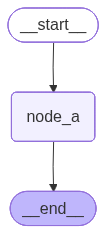

在该示例中，缓存的 **`ttl`** 被设置为 **`10s`**。

缓存失效前：

* 相同输入会命中缓存。
* 命中缓存时，节点函数不会再次执行。
* 因此不会打印 **`node_a 被调用`**。
* 输入不同则不会命中缓存，节点函数仍然会执行。

缓存失效后：

* 即使输入相同，也会再次执行节点函数。
* 执行完成后，会重新写入缓存。


## 5.5.4. 缓存策略配置详解

缓存策略通过 **`CachePolicy`** 配置，只有两个配置项

| 参数           | 描述                                  |
| :------------- | :------------------------------------ |
| **`key_func`** | 根据节点输入生成缓存 **`Key`** 的函数 |
| **`ttl`**      | 缓存键值对的存活时间，单位为秒        |

### 5.5.4.1. `key_func`

**`key_func`** 用于根据节点输入生成唯一的缓存 Key。

节点缓存本质上是一个 **`K-V`** 缓存：


```text
缓存 Key -> 节点运行结果
```


当节点再次执行时，LangGraph 会先根据当前输入计算缓存 Key：

* 如果缓存 Key 已存在，并且没有过期，则直接返回缓存结果。
* 如果缓存 Key 不存在，或者已经过期，则正常执行节点函数，并将结果写入缓存。

默认缓存键函数是 **`default_cache_key`**。

其核心实现如下：


```python
def default_cache_key(*args: Any, **kwargs: Any) -> str | bytes:
    """Default cache key function that uses the arguments and keyword arguments to generate a hashable key."""
    import pickle

    # protocol 5 strikes a good balance between speed and size
    return pickle.dumps((_freeze(args), _freeze(kwargs)), protocol=5, fix_imports=False)
```


它会把节点输入参数经过处理后，使用 **`pickle`** 序列化为字节序列，并将后者作为缓存 **`Key`**。

### 5.5.4.2. `ttl`

**`ttl`** 表示缓存的存活时间，单位为秒。

例如：


```python
CachePolicy(ttl=10)
```


表示缓存结果最多保存 10 秒。

如果设置为：


```python
CachePolicy(ttl=None)
```


表示缓存不会因为时间原因自动过期。

不过在实际项目中，不建议随意设置永久缓存。

如果节点依赖外部状态，例如：

* 当前时间
* 远程 API 数据
* 数据库查询结果
* 用户权限
* 环境变量
* 模型版本
* 提示词版本

那么应该根据业务场景设置合适的 **`ttl`**，或者把这些变量纳入缓存 Key 的计算逻辑。


## 5.6.1. 使用要求


默认配置功能要求：


```text
langgraph>=1.2
```


本课程当前环境为：


```text
langgraph==1.1.2
```


因此不支持该特性，本节只做概念说明。


## 5.6.2. 核心思想

当多个节点都需要配置相同的执行策略时，如果每个节点都重复配置，繁琐且耗时。

例如：


```python
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node(
    "node_b",
    node_b,
    retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node(
    "node_c",
    node_c,
    retry_policy=RetryPolicy(max_attempts=3)
)
```


在较新版本中，可以通过 **`set_node_defaults`** 为所有节点设置默认配置，即**全图默认配置 `Graph defaults`**。

默认配置可以包括：

* **`retry_policy`**
* **`timeout`**
* **`error_handler`**
* **`cache_policy`**

这样可以避免在每个 **`add_node`** 中重复相同配置。

本课程环境暂不支持，不展开实操。

参考官方文档

> https://docs.langchain.com/oss/python/langgraph/fault-tolerance#graph-defaults


## 5.7. 小结

本章介绍了 **`LangGraph`** 中节点执行与容错相关的能力。

总结如下：

| 机制                              | 机制类型         | 作用                       | 当前课程是否重点讲解          |
| :-------------------------------- | ---------------- | :------------------------- | :---------------------------- |
| **重试机制 `Retries`**            | 节点容错机制     | 节点失败后自动重试         | 是                            |
| **超时设置 `Timeouts`**           | 节点容错机制     | 限制单次节点执行时间       | 否，要求 **`langgraph>=1.2`** |
| **错误处理 `Error Handling`**     | 节点容错机制     | 重试耗尽后执行兜底逻辑     | 否，要求 **`langgraph>=1.2`** |
| **节点缓存 `Node Cache`**         | 节点执行优化机制 | 缓存节点历史运行结果       | 是                            |
| **全图默认配置 `Graph defaults`** | 默认策略配置     | 为所有节点设置默认执行策略 | 否，要求 **`langgraph>=1.2`** |

实际使用时，可以按照以下原则选择：

1. **临时性失败**：优先使用 **`RetryPolicy`**。
2. **外部服务可能卡住**：使用 **`timeout`** 控制单次节点执行时间。
3. **失败后需要兜底恢复**：使用 **`error_handler`**。
4. **相同输入重复执行且成本较高**：使用 **`CachePolicy`**。
5. **多个节点使用相同策略**：使用 **`set_node_defaults`** 统一配置。

其中，**重试机制** 和 **节点缓存** 是本课程的重点。


## 复习：拓扑与执行策略分开判断

`Send` 动态创建的是已注册节点的执行任务，不是在运行中修改图定义。汇聚节点负责处理汇总结果，字段 Reducer 负责合并更新；二者作用不同，名字相似也不能混用。

**面试提示**：等待两个上游完成，可用 `add_edge(["a", "b"], "join")`。分别写两条普通边表示独立触发；上游在不同超步结束时，下游可能执行多次。循环应有业务退出条件，递归限制只负责兜底。
